# Project 1 — Flow-Matching Imitation Learning on Gymnax Pendulum

This notebook builds the first Deep RL / imitation-learning project in stages:

1. Create and inspect `Pendulum-v1`.
2. Load the pretrained Gymnax PPO expert.
3. Evaluate the expert and collect demonstrations.
4. Train a deterministic behavioral-cloning baseline.
5. Train a conditional flow-matching policy.
6. Sample continuous actions by integrating the learned vector field with Diffrax.
7. Extend the flow policy to action chunks.
8. Compare expert, BC, one-step flow matching, and chunked flow matching.

The goal is to keep the implementation mathematically transparent while staying entirely in JAX/Flax.

## 0. Installation

Run this only if the packages are not already installed.

The pretrained checkpoint was produced by the older `gymnax-blines` repository, so `dotmap` is needed to unpickle its saved configuration.

In [1]:
# Uncomment if needed.
# %pip install -U jax flax optax gymnax diffrax matplotlib dotmap

## 1. Imports and configuration

We use one PRNG key throughout the notebook and split it whenever randomness is needed.

In [2]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
import flax.linen as nn
from flax.training import train_state
import optax
import diffrax
import gymnax

print("JAX version:", jax.__version__)
print("Devices:", jax.devices())

SEED = 0
key = jax.random.key(SEED)

JAX version: 0.11.1
Devices: [CudaDevice(id=0), CudaDevice(id=1)]


## 2. Create Pendulum-v1

The observation is

$$
s_t=(\cos\theta_t,\sin\theta_t,\dot\theta_t),
$$

and the action is a continuous scalar torque.

For this environment, the action dimension is one, which makes it a convenient first continuous-control problem for flow matching.

In [3]:
env, env_params = gymnax.make("Pendulum-v1")

key, reset_key = jax.random.split(key)
obs, env_state = env.reset(reset_key, env_params)

print("Observation:", obs)
print("Observation shape:", obs.shape)
print("Observation space:", env.observation_space(env_params))
print("Action space:", env.action_space(env_params))

Observation: [-0.99895006 -0.04581222 -0.9582176 ]
Observation shape: (3,)
Observation space: Box(low=[-1. -1. -8.], high=[1. 1. 8.], shape=(3,), dtype=float32)
Action space: Box(low=-2.0, high=2.0, shape=(1,), dtype=float32)


## 3. Inspect one transition

Gymnax 1.x separates `terminated` from `truncated`.  
The helper below also supports older five-output Gymnax environments, which makes the notebook a little more robust.

In [4]:
def env_step(env, env_params, key, state, action):
    out = env.step(key, state, action, env_params)

    # Gymnax 1.x: obs, state, reward, terminated, truncated, info
    if len(out) == 6:
        next_obs, next_state, reward, terminated, truncated, info = out
        done = terminated | truncated
        return next_obs, next_state, reward, done, terminated, truncated, info

    # Older Gymnax: obs, state, reward, done, info
    next_obs, next_state, reward, done, info = out
    return next_obs, next_state, reward, done, done, False, info


key, action_key, step_key = jax.random.split(key, 3)
action = env.action_space(env_params).sample(action_key)

next_obs, next_state, reward, done, terminated, truncated, info = env_step(
    env, env_params, step_key, env_state, action
)

print("Action:", action)
print("Next observation:", next_obs)
print("Reward:", reward)
print("Terminated:", terminated, "Truncated:", truncated)

Action: [-1.5828385]
Next observation: [-0.9998772   0.01567118 -1.2300026 ]
Reward: -9.678081
Terminated: False Truncated: False


## 4. Rollout implementations: slow reference first, then fast JAX version

We first write the most readable implementation with ordinary Python loops.

That version is useful for understanding the RL interaction loop, but it is inefficient in JAX because Python controls every environment step.

Then we write the JAX-native equivalent using `jax.lax.scan`, benchmark both versions, and use only the fast version afterward.

In [5]:
# -------------------------------------------------------------------------
# 4A. Slow reference rollout
# -------------------------------------------------------------------------
# This version is intentionally simple and readable.
#
# Why it is slow in JAX:
#   1. Python controls every time step.
#   2. JAX cannot compile the full trajectory as one computation.
#   3. Every step incurs Python <-> JAX dispatch overhead.
#   4. Converting arrays to NumPy inside the loop adds synchronization overhead.
#
# Keep this version as a conceptual reference only.

def rollout_slow(env, env_params, policy, params, key, max_steps=200):
    key, reset_key = jax.random.split(key)
    obs, state = env.reset(reset_key, env_params)

    observations, actions, rewards = [], [], []

    for _ in range(max_steps):
        key, policy_key, step_key = jax.random.split(key, 3)
        action = policy(params, obs, policy_key)

        next_obs, next_state, reward, done, _, _, _ = env_step(
            env, env_params, step_key, state, action
        )

        observations.append(np.asarray(obs))
        actions.append(np.asarray(action))
        rewards.append(float(reward))

        obs, state = next_obs, next_state
        if bool(done):
            break

    return {
        "observations": np.asarray(observations),
        "actions": np.asarray(actions),
        "rewards": np.asarray(rewards),
    }

In [6]:
# -------------------------------------------------------------------------
# 4B. Fast JAX-native rollout
# -------------------------------------------------------------------------
# `lax.scan` represents the time loop inside JAX.
#
# Benefits:
#   - the full trajectory can be JIT compiled,
#   - much less Python overhead,
#   - GPU/accelerator execution is more efficient,
#   - easy to combine with `vmap` for many episodes.

def rollout_scan(env, env_params, policy, params, key, max_steps=200):
    key, reset_key = jax.random.split(key)
    obs, state = env.reset(reset_key, env_params)

    def step_fn(carry, _):
        obs, state, key, done = carry
        key, policy_key, step_key = jax.random.split(key, 3)

        action = policy(params, obs, policy_key)
        next_obs, next_state, reward, step_done, _, _, _ = env_step(
            env, env_params, step_key, state, action
        )

        # After termination, hold the state fixed and zero later rewards.
        reward = jnp.where(done, 0.0, reward)
        next_obs = jnp.where(done, obs, next_obs)
        next_state = jax.tree_util.tree_map(
            lambda old, new: jnp.where(done, old, new),
            state, next_state
        )

        new_done = done | step_done
        return (next_obs, next_state, key, new_done), (obs, action, reward, new_done)

    init_carry = (obs, state, key, False)

    _, (observations, actions, rewards, dones) = jax.lax.scan(step_fn, init_carry, xs=None, length=max_steps)

    return {"observations": observations, "actions": actions, "rewards": rewards,"dones": dones,}


# Compile the entire trajectory.
rollout_fast = jax.jit(rollout_scan, static_argnames=("env", "policy", "max_steps"),)

### 4C. Compare slow and fast rollout speed

The first call to a JIT-compiled function includes compilation cost, so we warm it up once before timing.

After compilation, the fast version is the one we use for all subsequent computations.

In [7]:
import time

# Use the random policy here so the benchmark does not depend on the expert yet.
def random_policy(params, obs, key):
    return env.action_space(env_params).sample(key)


key, slow_key, fast_key, warmup_key = jax.random.split(key, 4)

# Warm up JIT compilation.
_ = rollout_fast(env, env_params, random_policy, None, warmup_key, max_steps=200)
jax.block_until_ready(_["rewards"])

# Time the Python-loop rollout.
t0 = time.perf_counter()
slow_traj = rollout_slow(env, env_params, random_policy, None, slow_key, max_steps=200)
slow_time = time.perf_counter() - t0

# Time the compiled rollout.
t0 = time.perf_counter()
fast_traj = rollout_fast(env, env_params, random_policy, None, fast_key, max_steps=200)
jax.block_until_ready(fast_traj["rewards"])
fast_time = time.perf_counter() - t0

print(f"Slow rollout: {slow_time:.4f} s")
print(f"Fast rollout: {fast_time:.4f} s")
print(f"Speedup:      {slow_time / fast_time:.1f}x")

Slow rollout: 0.7525 s
Fast rollout: 0.0072 s
Speedup:      104.4x


## 5. Policy evaluation: slow reference and fast batched version

The slow version evaluates episodes one at a time in Python.

The fast version uses

$$
\texttt{vmap over episodes}
\quad+\quad
\texttt{lax.scan over time}.
$$

After benchmarking both, the rest of the notebook uses only `evaluate_policy`.

In [8]:
# -------------------------------------------------------------------------
# 5A. Slow reference evaluation
# -------------------------------------------------------------------------
def evaluate_policy_slow(
    env, env_params, policy, params, key, num_episodes=20, max_steps=200
):
    returns = []

    for _ in range(num_episodes):
        key, rollout_key = jax.random.split(key)
        traj = rollout_slow(
            env, env_params, policy, params, rollout_key, max_steps=max_steps
        )
        returns.append(traj["rewards"].sum())

    returns = np.asarray(returns)
    return returns.mean(), returns.std(), returns

In [9]:
# -------------------------------------------------------------------------
# 5B. Fast vectorized evaluation
# -------------------------------------------------------------------------
def evaluate_policy(
    env, env_params, policy, params, key, num_episodes=20, max_steps=200
):
    episode_keys = jax.random.split(key, num_episodes)

    def one_episode(episode_key):
        traj = rollout_fast(
            env, env_params, policy, params, episode_key, max_steps=max_steps
        )
        return traj["rewards"].sum()

    returns = jax.vmap(one_episode)(episode_keys)
    return returns.mean(), returns.std(), returns

In [10]:
# -------------------------------------------------------------------------
# 5C. Compare evaluation speed
# -------------------------------------------------------------------------
key, slow_eval_key, fast_eval_key = jax.random.split(key, 3)

# Warm up the vectorized path.
warm_mean, warm_std, warm_returns = evaluate_policy(
    env, env_params, random_policy, None, fast_eval_key, num_episodes=20
)
jax.block_until_ready(warm_returns)

t0 = time.perf_counter()
slow_mean, slow_std, _ = evaluate_policy_slow(
    env, env_params, random_policy, None, slow_eval_key, num_episodes=20
)
slow_eval_time = time.perf_counter() - t0

t0 = time.perf_counter()
fast_mean, fast_std, fast_returns = evaluate_policy(
    env, env_params, random_policy, None, fast_eval_key, num_episodes=20
)
jax.block_until_ready(fast_returns)
fast_eval_time = time.perf_counter() - t0

print(f"Slow evaluation: {slow_eval_time:.4f} s")
print(f"Fast evaluation: {fast_eval_time:.4f} s")
print(f"Speedup:         {slow_eval_time / fast_eval_time:.1f}x")
print()
# Store the fast result under the canonical names used later in Part IV.
random_mean, random_std, random_returns = fast_mean, fast_std, fast_returns

print(
    f"Random-policy return (fast): "
    f"{float(random_mean):.1f} ± {float(random_std):.1f}"
)

Slow evaluation: 7.9576 s
Fast evaluation: 0.0128 s
Speedup:         619.9x

Random-policy return (fast): -1248.4 ± 321.2


From this point onward, all evaluation uses the fast JAX-native implementation:

```python
evaluate_policy(...)
```

The slow versions remain above only to make the performance difference explicit.

## 6. Load the pretrained PPO expert

The Gymnax baseline checkpoint stores a Flax parameter tree under `ckpt["network"]`.

Its configuration tells us that Pendulum uses a Gaussian actor-critic MLP with:

- two hidden layers,
- 64 hidden units per layer,
- separate actor and critic networks.

Set `GYMNAX_BLINES` below to the location of your cloned repository if needed.

In [11]:
GYMNAX_BLINES = "./gymnax-blines"
PPO_PATH = os.path.join(GYMNAX_BLINES, "agents", "Pendulum-v1", "ppo.pkl")

with open(PPO_PATH, "rb") as f:
    ppo_ckpt = pickle.load(f)

expert_params = ppo_ckpt["network"]
cfg = ppo_ckpt["train_config"]

print("Network:", cfg.network_name)
print("Hidden layers:", cfg.network_config.num_hidden_layers)
print("Hidden units:", cfg.network_config.num_hidden_units)

Network: Gaussian-MLP
Hidden layers: 2
Hidden units: 64


## 7. Reconstruct the PPO network

The layer names must match the checkpoint exactly.

For imitation learning we only need the actor mean, but the critic is included because its parameters are part of the saved Flax tree.

The actor predicts both a Gaussian mean and scale. For clean demonstrations we use the **mean action** instead of adding exploration noise.

In [12]:
def checkpoint_init(scale=0.05):
    return nn.initializers.uniform(scale)


class GaussianActorCritic(nn.Module):
    num_actions: int = 1
    hidden_dim: int = 64
    num_hidden_layers: int = 2
    min_std: float = 1e-3

    @nn.compact
    def __call__(self, x):
        # Critic branch: V(s)
        v = x
        for i in range(self.num_hidden_layers):
            v = nn.Dense(
                self.hidden_dim,
                name=f"critic_fc_{i+1}",
                bias_init=checkpoint_init(),
            )(v)
            v = nn.relu(v)
        value = nn.Dense(1, name="critic_fc_v", bias_init=checkpoint_init())(v)

        # Actor branch: Gaussian mean and scale
        h = x
        for i in range(self.num_hidden_layers):
            h = nn.Dense(
                self.hidden_dim,
                name=f"actor_fc_{i+1}",
                bias_init=checkpoint_init(),
            )(h)
            h = nn.relu(h)

        mu = nn.Dense(1, name="actor_fc_mu", bias_init=checkpoint_init())(h)
        log_scale = nn.Dense(1, name="actor_fc_scale", bias_init=checkpoint_init())(h)
        scale = jax.nn.softplus(log_scale) + self.min_std

        return value, mu, scale


expert_model = GaussianActorCritic(
    num_actions=1,
    hidden_dim=cfg.network_config.num_hidden_units,
    num_hidden_layers=cfg.network_config.num_hidden_layers,
)

## 8. Verify that the checkpoint matches the reconstructed network

If this cell runs without a Flax parameter-name/shape error, the checkpoint and architecture match.

In [13]:
value, mu, scale = expert_model.apply(expert_params, obs)

print("Value estimate:", value)
print("Expert mean action:", mu)
print("Expert action std:", scale)

Value estimate: [-279.90662]
Expert mean action: [-3.2801688]
Expert action std: [0.8899306]


## 9. PPO expert: mean policy versus sampled policy

The pretrained PPO actor defines a Gaussian policy

$$
a_t \sim \mathcal N(\mu_\theta(s_t), \sigma_\theta^2(s_t)).
$$

There are two natural ways to evaluate it:

- **Mean policy:** use $a_t=\mu_\theta(s_t)$.
- **Sampled policy:** sample from the Gaussian distribution learned by PPO.

For this checkpoint, the sampled policy performs substantially better than the deterministic mean policy. Therefore, the **sampled PPO policy is used as the expert demonstrator** throughout the rest of the notebook.

The deterministic mean policy is retained only as a diagnostic.

In [14]:
def expert_policy_mean(params, obs, key):
    # Deterministic diagnostic policy: use only the Gaussian mean.
    _, mu, _ = expert_model.apply(params, obs)
    return jnp.clip(mu, -2.0, 2.0)


def expert_policy(params, obs, key):
    # Actual demonstrator used in this notebook:
    # sample from the Gaussian PPO policy.
    _, mu, scale = expert_model.apply(params, obs)
    action = mu + scale * jax.random.normal(key, mu.shape)
    return jnp.clip(action, -2.0, 2.0)


# Compare both versions before selecting the demonstrator.
key, mean_eval_key, sample_eval_key = jax.random.split(key, 3)

mean_policy_mean, mean_policy_std, mean_policy_returns = evaluate_policy(
    env,
    env_params,
    expert_policy_mean,
    expert_params,
    mean_eval_key,
    num_episodes=100,
)

expert_mean, expert_std, expert_returns = evaluate_policy(
    env,
    env_params,
    expert_policy,
    expert_params,
    sample_eval_key,
    num_episodes=100,
)

print(
    f"PPO mean policy:    "
    f"{float(mean_policy_mean):.1f} ± {float(mean_policy_std):.1f}"
)

print(
    f"PPO sampled policy: "
    f"{float(expert_mean):.1f} ± {float(expert_std):.1f}"
)

print("\nUsing the sampled PPO policy as the expert demonstrator.")

PPO mean policy:    -464.8 ± 464.4
PPO sampled policy: -253.2 ± 208.9

Using the sampled PPO policy as the expert demonstrator.


## 10. Visualize one sampled expert trajectory

The trajectory below is generated by the stochastic PPO expert

$$
a_t \sim \pi_E(a_t\mid s_t).
$$

Because the policy is stochastic, two rollouts from the same initial-state distribution can produce different action sequences and returns.

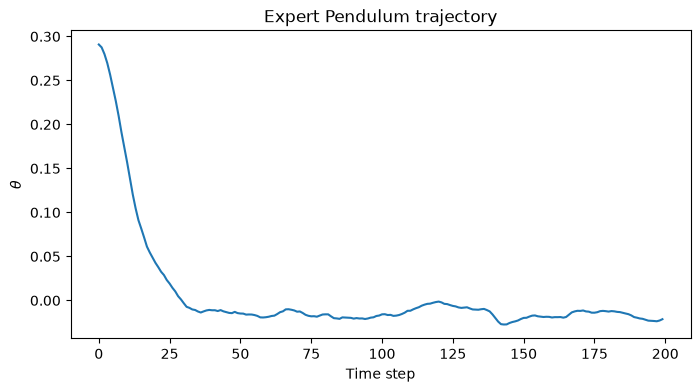

In [15]:
# From this point onward we use only the fast rollout implementation.
key, rollout_key = jax.random.split(key)

expert_traj = rollout_fast(
    env, env_params, expert_policy, expert_params, rollout_key, max_steps=200
)

obs_np = np.asarray(expert_traj["observations"])
theta = np.arctan2(obs_np[:, 1], obs_np[:, 0])

plt.figure(figsize=(8, 4))
plt.plot(theta)
plt.xlabel("Time step"); plt.ylabel(r"$\theta$")
plt.title("Expert Pendulum trajectory")
plt.show()

## 11. Expert data collection: sampled PPO demonstrations

The demonstration dataset is now generated from the **sampled PPO policy**, not the deterministic mean policy.

Therefore, for a fixed state $s$, the expert action is genuinely stochastic:

$$
a \sim \pi_E(a\mid s).
$$

This distinction matters:

- deterministic BC tends to learn something close to the conditional mean action,
- flow matching can in principle represent the full conditional action distribution,
- chunked flow can represent a joint distribution over short future action sequences.

We still compare slow and fast data-collection implementations below, then use only the fast vectorized collector for the full dataset.

In [16]:
# -------------------------------------------------------------------------
# 11A. Slow reference collector
# -------------------------------------------------------------------------
def collect_demonstrations_slow(
    env, env_params, policy, params, key, num_episodes=10, max_steps=200
):
    trajectories = []

    for _ in range(num_episodes):
        key, rollout_key = jax.random.split(key)
        trajectories.append(
            rollout_slow(
                env, env_params, policy, params, rollout_key, max_steps=max_steps
            )
        )

    return trajectories

In [17]:
# -------------------------------------------------------------------------
# 11B. Fast vectorized collector
# -------------------------------------------------------------------------
def collect_demonstrations(
    env, env_params, policy, params, key, num_episodes=100, max_steps=200
):
    episode_keys = jax.random.split(key, num_episodes)

    def one_episode(episode_key):
        traj = rollout_fast(
            env, env_params, policy, params, episode_key, max_steps=max_steps
        )
        return (
            traj["observations"],
            traj["actions"],
            traj["rewards"],
            traj["dones"],
        )

    observations, actions, rewards, dones = jax.vmap(one_episode)(episode_keys)

    return {
        "observations": observations,
        "actions": actions,
        "rewards": rewards,
        "dones": dones,
    }

In [18]:
# -------------------------------------------------------------------------
# 11C. Benchmark both collectors on the same small workload
# -------------------------------------------------------------------------
BENCH_EPISODES = 10
key, slow_data_key, fast_data_key = jax.random.split(key, 3)

# Warm up the fast collector.
warm_data = collect_demonstrations(
    env, env_params, expert_policy, expert_params,
    fast_data_key, num_episodes=BENCH_EPISODES
)
jax.block_until_ready(warm_data["rewards"])

t0 = time.perf_counter()
_ = collect_demonstrations_slow(
    env, env_params, expert_policy, expert_params,
    slow_data_key, num_episodes=BENCH_EPISODES
)
slow_collect_time = time.perf_counter() - t0

t0 = time.perf_counter()
fast_bench_data = collect_demonstrations(
    env, env_params, expert_policy, expert_params,
    fast_data_key, num_episodes=BENCH_EPISODES
)
jax.block_until_ready(fast_bench_data["rewards"])
fast_collect_time = time.perf_counter() - t0

print(f"Slow collection: {slow_collect_time:.4f} s")
print(f"Fast collection: {fast_collect_time:.4f} s")
print(f"Speedup:         {slow_collect_time / fast_collect_time:.1f}x")

Slow collection: 51.7112 s
Fast collection: 0.0164 s
Speedup:         3156.0x


In [19]:
# -------------------------------------------------------------------------
# 11D. Full expert dataset — fast version only
# -------------------------------------------------------------------------
key, data_key = jax.random.split(key)

expert_data = collect_demonstrations(
    env,
    env_params,
    expert_policy,
    expert_params,
    data_key,
    num_episodes=100,
    max_steps=200,
)

print("Observations:", expert_data["observations"].shape)
print("Actions:", expert_data["actions"].shape)
print("Rewards:", expert_data["rewards"].shape)

# Flatten episode/time dimensions for ordinary one-step imitation learning.
states = np.asarray(expert_data["observations"]).reshape(-1, 3)
actions = np.asarray(expert_data["actions"]).reshape(-1, 1)

print("Flattened states:", states.shape)
print("Flattened actions:", actions.shape)

Observations: (100, 200, 3)
Actions: (100, 200, 1)
Rewards: (100, 200)
Flattened states: (20000, 3)
Flattened actions: (20000, 1)


## 12. Train/validation split and observation normalization

We normalize observations because neural networks usually train more smoothly when their inputs have comparable scales.

The normalization statistics are computed from the training set only.

In [20]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(states))
split = int(0.9 * len(indices))

train_idx, val_idx = indices[:split], indices[split:]
s_train, a_train = states[train_idx], actions[train_idx]
s_val, a_val = states[val_idx], actions[val_idx]

obs_mean = s_train.mean(axis=0)
obs_std = s_train.std(axis=0) + 1e-6

s_train_n = (s_train - obs_mean) / obs_std
s_val_n = (s_val - obs_mean) / obs_std

print("Train:", s_train_n.shape, a_train.shape)
print("Validation:", s_val_n.shape, a_val.shape)

Train: (18000, 3) (18000, 1)
Validation: (2000, 3) (2000, 1)


# Part I — Deterministic Behavioral Cloning

The demonstration policy is stochastic, but this BC baseline is deterministic:

$$
a_\theta=f_\theta(s).
$$

With an MSE objective, deterministic BC tends to approximate the conditional mean expert action

$$
f_\theta(s)\approx \mathbb E[a\mid s].
$$

That is an important limitation here: the conditional mean of a stochastic control policy does not necessarily have the same closed-loop behavior as sampling from that policy.

This makes BC a useful baseline against the generative flow policy.

## 13. Behavioral-cloning network

In [21]:
class BCPolicy(nn.Module):
    hidden_dim: int = 128

    @nn.compact
    def __call__(self, obs):
        x = nn.relu(nn.Dense(self.hidden_dim)(obs))
        x = nn.relu(nn.Dense(self.hidden_dim)(x))
        return 2.0 * nn.tanh(nn.Dense(1)(x))


bc_model = BCPolicy()
key, init_key = jax.random.split(key)
bc_params = bc_model.init(init_key, jnp.zeros((3,)))

bc_state = train_state.TrainState.create(
    apply_fn=bc_model.apply,
    params=bc_params,
    tx=optax.adam(3e-4),
)

## 14. Behavioral-cloning update

The target is the expert torque, so the supervised objective is simply

$$
\mathcal L_{BC}=\mathbb E\|f_\theta(s)-a_E\|^2.
$$

In [22]:
@jax.jit
def bc_train_step(state, obs, actions):
    def loss_fn(params):
        pred = state.apply_fn(params, obs)
        return jnp.mean((pred - actions) ** 2)

    loss, grads = jax.value_and_grad(loss_fn)(state.params)
    return state.apply_gradients(grads=grads), loss


def minibatches(x, y, batch_size, rng):
    idx = rng.permutation(len(x))
    for start in range(0, len(x), batch_size):
        batch = idx[start:start + batch_size]
        yield jnp.asarray(x[batch]), jnp.asarray(y[batch])

## 15. Train BC

The loop is intentionally explicit so the supervised-learning part remains easy to inspect.

In [23]:
bc_losses = []
rng = np.random.default_rng(SEED)

for epoch in range(50):
    epoch_losses = []

    for s_b, a_b in minibatches(s_train_n, a_train, 256, rng):
        bc_state, loss = bc_train_step(bc_state, s_b, a_b)
        epoch_losses.append(float(loss))

    bc_losses.append(np.mean(epoch_losses))

    if epoch % 10 == 0 or epoch == 49:
        print(f"Epoch {epoch:02d} | BC loss = {bc_losses[-1]:.6f}")

Epoch 00 | BC loss = 0.428996
Epoch 10 | BC loss = 0.270570
Epoch 20 | BC loss = 0.263618
Epoch 30 | BC loss = 0.266167
Epoch 40 | BC loss = 0.264196
Epoch 49 | BC loss = 0.262639


## 16. Evaluate BC in closed loop

Supervised validation loss is not enough in imitation learning.  
A policy can make small one-step errors that compound when it controls the environment.

So the main metric is the actual episode return.

In [24]:
obs_mean_j = jnp.asarray(obs_mean)
obs_std_j = jnp.asarray(obs_std)

def bc_policy(params, obs, key):
    obs_n = (obs - obs_mean_j) / obs_std_j
    return bc_model.apply(params, obs_n)


key, eval_key = jax.random.split(key)
bc_mean, bc_std, bc_returns = evaluate_policy(
    env, env_params, bc_policy, bc_state.params, eval_key, num_episodes=50
)

print(f"BC return: {bc_mean:.1f} ± {bc_std:.1f}")

BC return: -211.9 ± 193.1


# Part II — One-Step Flow-Matching Policy

Instead of directly regressing the expert action, we model a conditional vector field in action space.

For an expert action $x_1=a_E$, draw noise

$$
x_0\sim\mathcal N(0,I),
$$

sample $t\sim U[0,1]$, and define

$$
x_t=(1-t)x_0+t x_1.
$$

The target velocity is therefore

$$
u_t=x_1-x_0.
$$

The network learns

$$
v_\theta(t,x_t,s)\approx u_t.
$$

## 17. Flow network

In [25]:
class FlowPolicy(nn.Module):
    output_dim: int
    hidden_dim: int = 128

    @nn.compact
    def __call__(self, t, x, obs):
        # Make scalar time compatible with batched and unbatched inputs.
        t = jnp.asarray(t)
        if x.ndim == 1:
            t_feat = jnp.reshape(t, (1,))
        else:
            t_feat = jnp.broadcast_to(t[..., None], (*x.shape[:-1], 1))

        z = jnp.concatenate([obs, x, t_feat], axis=-1)
        z = nn.silu(nn.Dense(self.hidden_dim)(z))
        z = nn.silu(nn.Dense(self.hidden_dim)(z))
        return nn.Dense(self.output_dim)(z)


flow_model = FlowPolicy(output_dim=1)
key, init_key = jax.random.split(key)
flow_params = flow_model.init(
    init_key,
    jnp.asarray(0.5),
    jnp.zeros((1,)),
    jnp.zeros((3,)),
)

flow_state = train_state.TrainState.create(
    apply_fn=flow_model.apply,
    params=flow_params,
    tx=optax.adam(3e-4),
)

## 18. Flow-matching training step

Every batch creates fresh Gaussian noise and fresh interpolation times.

In [26]:
@jax.jit
def flow_train_step(state, obs, target_actions, key):
    key_x, key_t = jax.random.split(key)
    x0 = jax.random.normal(key_x, target_actions.shape)
    t = jax.random.uniform(key_t, (target_actions.shape[0],))

    xt = (1.0 - t[:, None]) * x0 + t[:, None] * target_actions
    target_velocity = target_actions - x0

    def loss_fn(params):
        pred_velocity = state.apply_fn(params, t, xt, obs)
        return jnp.mean((pred_velocity - target_velocity) ** 2)

    loss, grads = jax.value_and_grad(loss_fn)(state.params)
    return state.apply_gradients(grads=grads), loss

## 19. Train one-step flow matching

In [27]:
flow_losses = []
rng = np.random.default_rng(SEED)

for epoch in range(50):
    epoch_losses = []

    for s_b, a_b in minibatches(s_train_n, a_train, 256, rng):
        key, train_key = jax.random.split(key)
        flow_state, loss = flow_train_step(flow_state, s_b, a_b, train_key)
        epoch_losses.append(float(loss))

    flow_losses.append(np.mean(epoch_losses))

    if epoch % 10 == 0 or epoch == 49:
        print(f"Epoch {epoch:02d} | FM loss = {flow_losses[-1]:.6f}")

Epoch 00 | FM loss = 1.530263
Epoch 10 | FM loss = 0.677850
Epoch 20 | FM loss = 0.570289
Epoch 30 | FM loss = 0.512739
Epoch 40 | FM loss = 0.499504
Epoch 49 | FM loss = 0.477254


## 20. Diffrax flow sampler

At inference time we start from Gaussian noise and integrate

$$
\frac{dx_t}{dt}=v_\theta(t,x_t,s), \qquad t:0\rightarrow1.
$$

We begin with a fixed-step Heun solver.  
Later we can compare Euler, Heun, and adaptive solvers.

In [28]:
def integrate_flow(model, params, obs_n, key, output_dim, solver=None, dt0=0.05):
    x0 = jax.random.normal(key, (output_dim,))
    solver = diffrax.Heun() if solver is None else solver

    def vector_field(t, x, args):
        obs_condition = args
        return model.apply(params, t, x, obs_condition)

    sol = diffrax.diffeqsolve(
        diffrax.ODETerm(vector_field),
        solver,
        t0=0.0,
        t1=1.0,
        dt0=dt0,
        y0=x0,
        args=obs_n,
        saveat=diffrax.SaveAt(t1=True),
    )

    return sol.ys[-1]

## 21. One-step flow policy and evaluation

In [29]:
def flow_policy(params, obs, key):
    obs_n = (obs - obs_mean_j) / obs_std_j
    action = integrate_flow(flow_model, params, obs_n, key, output_dim=1)
    return jnp.clip(action, -2.0, 2.0)


key, eval_key = jax.random.split(key)
flow_mean, flow_std, flow_returns = evaluate_policy(
    env, env_params, flow_policy, flow_state.params, eval_key, num_episodes=50
)

print(f"Flow return: {flow_mean:.1f} ± {flow_std:.1f}")

Flow return: -308.3 ± 236.9


# Part III — Flow Matching with Action Chunks

Now the target is no longer one action.

For chunk length $H$,

$$
x_1=[a_t,a_{t+1},\ldots,a_{t+H-1}]\in\mathbb R^H.
$$

The flow-matching objective is unchanged; only the dimensionality of the generated object changes.

We begin with `H = 8`.

## 22. Build the action-chunk dataset

Chunks are created **within individual trajectories**, so they never cross episode boundaries.

In [30]:
# Action-chunk horizon.
# The flow model generates CHUNK_H actions at each planning step.
CHUNK_H = 8

# Replanning interval.
# The controller executes the first REPLAN_K actions from the generated chunk,
# then observes the new state and generates a fresh chunk.
#
#   REPLAN_K = 1       -> fully closed-loop / replan every environment step
#   REPLAN_K = CHUNK_H -> execute the entire generated chunk open-loop
REPLAN_K = 1

assert 1 <= REPLAN_K <= CHUNK_H


def make_chunk_dataset(dataset, horizon):
    # Vectorized expert data has shape:
    #   observations: [num_episodes, time, obs_dim]
    #   actions:      [num_episodes, time, action_dim]
    observations = np.asarray(dataset["observations"])
    actions = np.asarray(dataset["actions"])

    chunk_states, chunks = [], []

    # Construct windows independently inside every episode so that
    # an action chunk never crosses an episode boundary.
    for episode in range(observations.shape[0]):
        obs_ep = observations[episode]
        act_ep = actions[episode]

        for t in range(act_ep.shape[0] - horizon + 1):
            chunk_states.append(obs_ep[t])
            chunks.append(act_ep[t:t + horizon].reshape(-1))

    return np.asarray(chunk_states), np.asarray(chunks)


chunk_states, action_chunks = make_chunk_dataset(expert_data, CHUNK_H)
chunk_states_n = (chunk_states - obs_mean) / obs_std

print("Chunk horizon H:", CHUNK_H)
print("Replanning interval K:", REPLAN_K)
print("Chunk states:", chunk_states_n.shape)
print("Action chunks:", action_chunks.shape)

Chunk horizon H: 8
Replanning interval K: 1
Chunk states: (19300, 3)
Action chunks: (19300, 8)


## 23. Chunked flow network

The same architecture now outputs an `H`-dimensional velocity.

In [31]:
chunk_model = FlowPolicy(output_dim=CHUNK_H)

key, init_key = jax.random.split(key)
chunk_params = chunk_model.init(
    init_key,
    jnp.asarray(0.5),
    jnp.zeros((CHUNK_H,)),
    jnp.zeros((3,)),
)

chunk_state = train_state.TrainState.create(
    apply_fn=chunk_model.apply,
    params=chunk_params,
    tx=optax.adam(3e-4),
)

## 24. Train the chunked flow model

We can reuse the same flow-matching update because it is dimension-agnostic.

In [32]:
chunk_losses = []
rng = np.random.default_rng(SEED)

for epoch in range(50):
    epoch_losses = []

    for s_b, a_b in minibatches(chunk_states_n, action_chunks, 256, rng):
        key, train_key = jax.random.split(key)
        chunk_state, loss = flow_train_step(chunk_state, s_b, a_b, train_key)
        epoch_losses.append(float(loss))

    chunk_losses.append(np.mean(epoch_losses))

    if epoch % 10 == 0 or epoch == 49:
        print(f"Epoch {epoch:02d} | Chunk FM loss = {chunk_losses[-1]:.6f}")

Epoch 00 | Chunk FM loss = 1.592011
Epoch 10 | Chunk FM loss = 0.799936
Epoch 20 | Chunk FM loss = 0.696432
Epoch 30 | Chunk FM loss = 0.660011
Epoch 40 | Chunk FM loss = 0.625939
Epoch 49 | Chunk FM loss = 0.606484


## 25. Receding-horizon chunked policy

At every environment step:

1. generate an entire action chunk,
2. execute only the first action,
3. observe the new state,
4. generate a fresh chunk.

This retains feedback at every time step while still training the generative model to represent short action trajectories.

In [33]:
# -------------------------------------------------------------------------
# 25. Chunk planner
# -------------------------------------------------------------------------
# This function generates an entire action chunk.
# It does NOT decide how many of those actions are executed; that is handled
# by the dedicated chunked rollout below through REPLAN_K.

def generate_action_chunk(params, obs, key):
    obs_n = (obs - obs_mean_j) / obs_std_j
    chunk = integrate_flow(
        chunk_model,
        params,
        obs_n,
        key,
        output_dim=CHUNK_H,
    )
    return jnp.clip(chunk, -2.0, 2.0)


# -------------------------------------------------------------------------
# 26. Chunked rollout with replanning interval K
# -------------------------------------------------------------------------
# At a planning step:
#   1. Generate H actions.
#   2. Execute the first K actions sequentially.
#   3. Replan from the newly observed state.
#
# Because the inner K-step execution is sequential, we use `lax.scan` there.
# The outer planning loop is also implemented with `lax.scan`, so the whole
# controller remains JAX-native and JIT-compilable.

def chunked_rollout_scan(
    env,
    env_params,
    params,
    key,
    chunk_h=CHUNK_H,
    replan_k=REPLAN_K,
    max_steps=200,
):
    assert replan_k <= chunk_h

    key, reset_key = jax.random.split(key)
    obs, state = env.reset(reset_key, env_params)

    # Number of planning events needed to cover max_steps.
    num_plans = (max_steps + replan_k - 1) // replan_k

    def planning_step(carry, _):
        obs, state, key, done, global_step = carry
        key, plan_key = jax.random.split(key)

        # Generate H candidate actions from the current state.
        chunk = generate_action_chunk(params, obs, plan_key)

        def execute_one(carry_inner, action):
            obs, state, key, done, global_step = carry_inner
            key, step_key = jax.random.split(key)

            # If max_steps has already been reached or episode is done,
            # keep state fixed and emit zero reward.
            inactive = done | (global_step >= max_steps)

            next_obs, next_state, reward, step_done, _, _, _ = env_step(
                env, env_params, step_key, state, action
            )

            reward = jnp.where(inactive, 0.0, reward)
            next_obs = jnp.where(inactive, obs, next_obs)
            next_state = jax.tree_util.tree_map(
                lambda old, new: jnp.where(inactive, old, new),
                state,
                next_state,
            )

            new_done = done | step_done
            new_global_step = global_step + jnp.where(inactive, 0, 1)

            new_carry = (
                next_obs,
                next_state,
                key,
                new_done,
                new_global_step,
            )

            output = (
                obs,
                action,
                reward,
                new_done,
            )

            return new_carry, output

        # Execute only the first K actions from the generated H-step chunk.
        inner_init = (obs, state, key, done, global_step)
        inner_final, outputs = jax.lax.scan(
            execute_one,
            inner_init,
            chunk[:replan_k],
        )

        next_obs, next_state, key, next_done, next_global_step = inner_final

        return (
            next_obs,
            next_state,
            key,
            next_done,
            next_global_step,
        ), outputs

    init = (obs, state, key, False, jnp.asarray(0))

    _, outputs = jax.lax.scan(
        planning_step,
        init,
        xs=None,
        length=num_plans,
    )

    observations, actions, rewards, dones = outputs

    # Flatten [num_plans, K, ...] into one time dimension.
    observations = observations.reshape((-1,) + observations.shape[2:])
    actions = actions.reshape((-1,) + actions.shape[2:])
    rewards = rewards.reshape(-1)
    dones = dones.reshape(-1)

    # Remove the extra padded steps created by ceil(max_steps / K).
    observations = observations[:max_steps]
    actions = actions[:max_steps]
    rewards = rewards[:max_steps]
    dones = dones[:max_steps]

    return {
        "observations": observations,
        "actions": actions,
        "rewards": rewards,
        "dones": dones,
    }


# Compile with H, K, and max_steps treated as static control-flow parameters.
chunked_rollout_fast = jax.jit(
    chunked_rollout_scan,
    static_argnames=("env", "chunk_h", "replan_k", "max_steps"),
)


def evaluate_chunked_policy(
    env,
    env_params,
    params,
    key,
    num_episodes=50,
    chunk_h=CHUNK_H,
    replan_k=REPLAN_K,
    max_steps=200,
):
    episode_keys = jax.random.split(key, num_episodes)

    def one_episode(episode_key):
        traj = chunked_rollout_fast(
            env,
            env_params,
            params,
            episode_key,
            chunk_h=chunk_h,
            replan_k=replan_k,
            max_steps=max_steps,
        )
        return traj["rewards"].sum()

    returns = jax.vmap(one_episode)(episode_keys)
    return returns.mean(), returns.std(), returns


key, eval_key = jax.random.split(key)
chunk_mean, chunk_std, chunk_returns = evaluate_chunked_policy(
    env,
    env_params,
    chunk_state.params,
    eval_key,
    num_episodes=50,
    chunk_h=CHUNK_H,
    replan_k=REPLAN_K,
)

print(
    f"Chunked flow (H={CHUNK_H}, K={REPLAN_K}): "
    f"{float(chunk_mean):.1f} ± {float(chunk_std):.1f}"
)

Chunked flow (H=8, K=1): -272.4 ± 166.8


## 27. Sweep the replanning interval $K$

The flow model always generates $H$ actions, but we can vary how many are executed before replanning.

With `CHUNK_H = 8`, we compare:

$$
K\in\{1,2,4,8\}.
$$

Interpretation:

- $K=1$: maximum feedback; replan every step.
- $K=2,4$: partial open-loop execution.
- $K=H$: execute the whole generated chunk before replanning.

This experiment directly measures the tradeoff between feedback and temporal commitment.

In [34]:
# Gather final evaluation statistics.
# The main chunked result below corresponds to the currently selected REPLAN_K.
results = {
    "Random": (random_mean, random_std),
    "PPO Expert (sampled)": (expert_mean, expert_std),
    "BC": (bc_mean, bc_std),
    "Flow": (flow_mean, flow_std),
    f"Chunked Flow H={CHUNK_H}, K={REPLAN_K}": (chunk_mean, chunk_std),
}

names = list(results.keys())
means = np.asarray([float(results[name][0]) for name in names])
stds = np.asarray([float(results[name][1]) for name in names])

for name, mean, std in zip(names, means, stds):
    print(f"{name:28s}: {mean:8.1f} ± {std:.1f}")

Random                      :  -1248.4 ± 321.2
PPO Expert (sampled)        :   -253.2 ± 208.9
BC                          :   -211.9 ± 193.1
Flow                        :   -308.3 ± 236.9
Chunked Flow H=8, K=1       :   -272.4 ± 166.8


## Common validation metric: sampled expert-action MSE

The BC loss and flow-matching loss are **not directly comparable** because they optimize different targets.

BC minimizes action regression error, while flow matching minimizes vector-field error.

Because the expert is stochastic, each recorded demonstration contains one sampled action

$$
a_E \sim \pi_E(a\mid s).
$$

To compare the learned policies using a common quantity, we measure

$$
\mathbb E\left[\|\hat a(s)-a_E\|^2\right]
$$

against the sampled expert actions stored in the validation dataset.

This metric should be interpreted carefully: for a stochastic expert, a deterministic BC policy can have nonzero MSE even if it predicts the conditional mean correctly.

For the stochastic flow policy we also estimate conditional action variance across multiple base-noise samples.

In [35]:
# -------------------------------------------------------------------------
# Common action-space diagnostic
# -------------------------------------------------------------------------
# Diffrax sampling is more expensive than a direct BC forward pass, so we
# evaluate on a random subset of the validation set.
DIAG_N = min(512, len(s_val_n))
FLOW_MC_SAMPLES = 4

diag_rng = np.random.default_rng(SEED)
diag_idx = diag_rng.choice(len(s_val_n), size=DIAG_N, replace=False)

diag_states_n = jnp.asarray(s_val_n[diag_idx])
diag_actions = jnp.asarray(a_val[diag_idx])

# ----- BC predictions -----------------------------------------------------
bc_pred = jax.vmap(lambda s: bc_model.apply(bc_state.params, s))(diag_states_n)
bc_action_mse = jnp.mean((bc_pred - diag_actions) ** 2)


# ----- One-step flow predictions -----------------------------------------
# One stochastic action sample for every validation state.
def sample_flow_action(params, state_n, key):
    action = integrate_flow(
        flow_model,
        params,
        state_n,
        key,
        output_dim=1,
    )
    return jnp.clip(action, -2.0, 2.0)

key, flow_diag_key = jax.random.split(key)
flow_keys = jax.random.split(flow_diag_key, DIAG_N)

flow_pred = jax.vmap(
    lambda s, k: sample_flow_action(flow_state.params, s, k)
)(diag_states_n, flow_keys)

flow_action_mse = jnp.mean((flow_pred - diag_actions) ** 2)


# ----- Chunked-flow predictions ------------------------------------------
# To compare against the expert's current action, use only the first action
# of the generated H-step chunk.
def sample_chunk_first_action(params, state_n, key):
    chunk = integrate_flow(
        chunk_model,
        params,
        state_n,
        key,
        output_dim=CHUNK_H,
    )
    return jnp.clip(chunk[:1], -2.0, 2.0)

key, chunk_diag_key = jax.random.split(key)
chunk_keys = jax.random.split(chunk_diag_key, DIAG_N)

chunk_pred = jax.vmap(
    lambda s, k: sample_chunk_first_action(chunk_state.params, s, k)
)(diag_states_n, chunk_keys)

chunk_action_mse = jnp.mean((chunk_pred - diag_actions) ** 2)


# ----- Flow stochasticity diagnostic -------------------------------------
# For each state, generate several flow samples and measure the variance of
# the produced action. BC is deterministic, so its conditional variance is 0.
key, variance_key = jax.random.split(key)

# Create one master key per validation state, then split each master key
# into FLOW_MC_SAMPLES independent keys.
#
# This is preferable to reshaping raw key arrays:
# - modern JAX typed keys have scalar shape (),
# - older PRNGKey keys have shape (2,),
# and nested splitting works correctly with either representation.
state_keys = jax.random.split(variance_key, DIAG_N)
mc_keys = jax.vmap(
    lambda k: jax.random.split(k, FLOW_MC_SAMPLES)
)(state_keys)

def flow_samples_for_state(state_n, keys):
    return jax.vmap(
        lambda k: sample_flow_action(flow_state.params, state_n, k)
    )(keys)

flow_mc_actions = jax.vmap(flow_samples_for_state)(
    diag_states_n, mc_keys
)

# Shape: [num_states, num_samples, action_dim]
flow_action_variance = jnp.mean(jnp.var(flow_mc_actions, axis=1))


print(f"Validation states used: {DIAG_N}")
print(f"BC action MSE:           {float(bc_action_mse):.6f}")
print(f"Flow action MSE:         {float(flow_action_mse):.6f}")
print(f"Chunked-flow action MSE: {float(chunk_action_mse):.6f}")
print(f"Flow action variance:    {float(flow_action_variance):.6f}")

Validation states used: 512
BC action MSE:           0.171128
Flow action MSE:         0.391747
Chunked-flow action MSE: 0.436745
Flow action variance:    0.168010


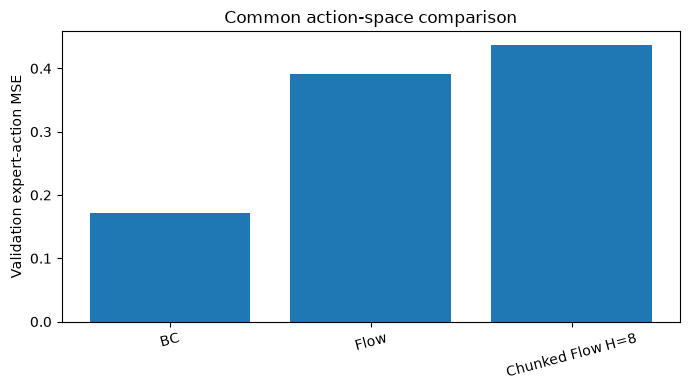

In [36]:
# Put the common metric in one plot.
diagnostic_names = ["BC", "Flow", f"Chunked Flow H={CHUNK_H}"]
diagnostic_mse = [
    float(bc_action_mse),
    float(flow_action_mse),
    float(chunk_action_mse),
]

plt.figure(figsize=(7, 4))
plt.bar(diagnostic_names, diagnostic_mse)
plt.ylabel("Validation expert-action MSE")
plt.title("Common action-space comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Part IV — Compare the policies

In [37]:
# Gather all final evaluation statistics in one place.
# Every variable below has been produced by the fast evaluation function.
results = {
    "Random": (random_mean, random_std),
    "PPO Expert (sampled)": (expert_mean, expert_std),
    "BC": (bc_mean, bc_std),
    "Flow": (flow_mean, flow_std),
    f"Chunked Flow H={CHUNK_H}": (chunk_mean, chunk_std),
}

names = list(results.keys())
means = np.asarray([float(results[name][0]) for name in names])
stds = np.asarray([float(results[name][1]) for name in names])

for name, mean, std in zip(names, means, stds):
    print(f"{name:20s}: {mean:8.1f} ± {std:.1f}")

Random              :  -1248.4 ± 321.2
PPO Expert (sampled):   -253.2 ± 208.9
BC                  :   -211.9 ± 193.1
Flow                :   -308.3 ± 236.9
Chunked Flow H=8    :   -272.4 ± 166.8


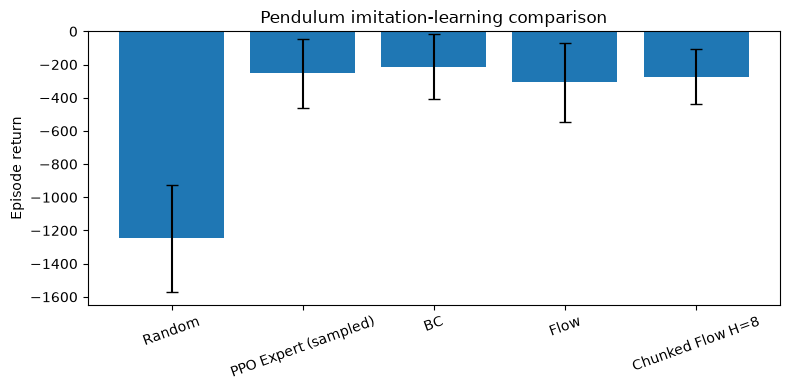

In [38]:
plt.figure(figsize=(8, 4))
plt.bar(names, means, yerr=stds, capsize=4)
plt.ylabel("Episode return")
plt.xticks(rotation=20)
plt.title("Pendulum imitation-learning comparison")
plt.tight_layout()
plt.show()

## 26. Training curves

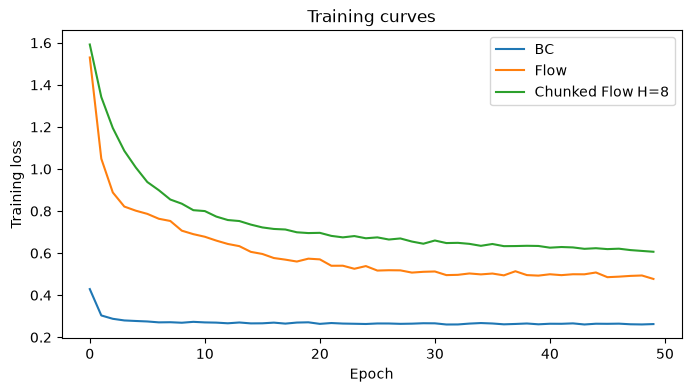

In [39]:
plt.figure(figsize=(8, 4))
plt.plot(bc_losses, label="BC")
plt.plot(flow_losses, label="Flow")
plt.plot(chunk_losses, label=f"Chunked Flow H={CHUNK_H}")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.legend()
plt.title("Training curves")
plt.show()

# Part V — Systematic study of chunk horizon $H$ and replanning interval $K$

Everything above remains the **baseline experiment with $H=8$**.

We now extend that experiment systematically.

$$
H = \text{number of actions generated by the flow model},
$$

while

$$
K = \text{number of those actions executed before replanning}.
$$

Changing $H$ changes the dimensionality of the learned flow model, so a **separate model must be trained for each $H$**.

Changing $K$ only changes how a trained chunk is executed, so the same model for a fixed $H$ can be evaluated with several values of $K$.

We use

$$
H\in\{1,2,4,8,16\}
$$

and, for each $H$, evaluate the valid values

$$
K\in\{1,2,4,8,16\}, \qquad K\le H.
$$

The already-trained $H=8$ baseline model is reused rather than trained again.

## 28. General rollout for an arbitrary chunk horizon

The earlier chunked rollout is tied to the baseline `CHUNK_H = 8`.

For the systematic experiment we create a rollout factory. Given a trained model and its horizon $H$, it returns a compiled rollout function that can be evaluated at any valid replanning interval $K\le H$.

In [40]:
def make_hk_rollout(model, H):
    # Create a JIT-compiled chunked rollout for one fixed horizon H.

    def generate_chunk(params, obs, key):
        obs_n = (obs - obs_mean_j) / obs_std_j

        chunk = integrate_flow(
            model,
            params,
            obs_n,
            key,
            output_dim=H,
        )

        return jnp.clip(chunk, -2.0, 2.0)

    def rollout_hk(
        env,
        env_params,
        params,
        key,
        replan_k=1,
        max_steps=200,
    ):
        assert replan_k <= H

        key, reset_key = jax.random.split(key)
        obs, state = env.reset(reset_key, env_params)

        num_plans = (max_steps + replan_k - 1) // replan_k

        def planning_step(carry, _):
            obs, state, key, done, global_step = carry
            key, plan_key = jax.random.split(key)

            chunk = generate_chunk(params, obs, plan_key)

            def execute_one(inner_carry, action):
                obs, state, key, done, global_step = inner_carry
                key, step_key = jax.random.split(key)

                inactive = done | (global_step >= max_steps)

                next_obs, next_state, reward, step_done, _, _, _ = env_step(
                    env,
                    env_params,
                    step_key,
                    state,
                    action,
                )

                reward = jnp.where(inactive, 0.0, reward)
                next_obs = jnp.where(inactive, obs, next_obs)

                next_state = jax.tree_util.tree_map(
                    lambda old, new: jnp.where(inactive, old, new),
                    state,
                    next_state,
                )

                new_done = done | step_done
                new_step = global_step + jnp.where(inactive, 0, 1)

                return (
                    next_obs,
                    next_state,
                    key,
                    new_done,
                    new_step,
                ), (
                    obs,
                    action,
                    reward,
                    new_done,
                )

            inner_init = (obs, state, key, done, global_step)

            inner_final, outputs = jax.lax.scan(
                execute_one,
                inner_init,
                chunk[:replan_k],
            )

            next_obs, next_state, key, next_done, next_step = inner_final

            return (
                next_obs,
                next_state,
                key,
                next_done,
                next_step,
            ), outputs

        init = (obs, state, key, False, jnp.asarray(0))

        _, outputs = jax.lax.scan(
            planning_step,
            init,
            xs=None,
            length=num_plans,
        )

        observations, actions, rewards, dones = outputs

        observations = observations.reshape((-1,) + observations.shape[2:])
        actions = actions.reshape((-1,) + actions.shape[2:])
        rewards = rewards.reshape(-1)
        dones = dones.reshape(-1)

        return {
            "observations": observations[:max_steps],
            "actions": actions[:max_steps],
            "rewards": rewards[:max_steps],
            "dones": dones[:max_steps],
        }

    return jax.jit(
        rollout_hk,
        static_argnames=("env", "replan_k", "max_steps"),
    )

## 29. Evaluation helper for one $(H,K)$ pair

For a fixed trained $H$-model, this evaluates many independent episodes in parallel with `vmap`.

In [41]:
def evaluate_hk_model(
    rollout_fn,
    env,
    env_params,
    params,
    key,
    K,
    num_episodes=100,
    max_steps=200,
):
    episode_keys = jax.random.split(key, num_episodes)

    def one_episode(ep_key):
        traj = rollout_fn(
            env,
            env_params,
            params,
            ep_key,
            replan_k=K,
            max_steps=max_steps,
        )
        return traj["rewards"].sum()

    returns = jax.vmap(one_episode)(episode_keys)
    return returns.mean(), returns.std(), returns

## 30. Train separate flow models for different $H$

The original $H=8$ model from Part III is reused.

New models are trained for

$$
H\in\{1,2,4,16\}.
$$

For each horizon we store the model, parameters, training losses, and compiled rollout function.

In [42]:
H_VALUES = [1, 2, 3, 4, 5, 6,7,8, 9,10,11, 12, 13, 14, 15, 16]
K_CANDIDATES = [1, 2, 3, 4, 5, 6,7,8, 9,10,11, 12, 13, 14, 15, 16]

SWEEP_EPOCHS = 50
SWEEP_BATCH_SIZE = 256
SWEEP_LR = 3e-4
SWEEP_EVAL_EPISODES = 100
SWEEP_MAX_STEPS = 200

models_h = {}
hk_results = {}


# Reuse the already-trained H=8 baseline from Part III.
models_h[8] = {
    "model": chunk_model,
    "state": chunk_state,
    "losses": np.asarray(chunk_losses),
    "rollout": make_hk_rollout(chunk_model, 8),
}


# Train only the horizons that do not already have a model.
for H in H_VALUES:
    if H == 8:
        print("H=8: reusing the baseline model trained in Part III.")
        continue

    print("\n" + "=" * 65)
    print(f"Training flow model for chunk horizon H={H}")
    print("=" * 65)

    states_h, actions_h = make_chunk_dataset(expert_data, H)
    states_h_n = (states_h - obs_mean) / obs_std

    print("State inputs:", states_h_n.shape)
    print("Action targets:", actions_h.shape)

    model_h = FlowPolicy(output_dim=H)

    key, init_key = jax.random.split(key)
    params_h = model_h.init(
        init_key,
        jnp.asarray(0.5),
        jnp.zeros((H,)),
        jnp.zeros((3,)),
    )

    state_h = train_state.TrainState.create(
        apply_fn=model_h.apply,
        params=params_h,
        tx=optax.adam(SWEEP_LR),
    )

    losses_h = []
    rng_h = np.random.default_rng(SEED)

    for epoch in range(SWEEP_EPOCHS):
        epoch_losses = []

        for s_b, a_b in minibatches(
            states_h_n,
            actions_h,
            SWEEP_BATCH_SIZE,
            rng_h,
        ):
            key, train_key = jax.random.split(key)

            state_h, loss = flow_train_step(
                state_h,
                s_b,
                a_b,
                train_key,
            )

            epoch_losses.append(float(loss))

        mean_loss = np.mean(epoch_losses)
        losses_h.append(mean_loss)

        if epoch % 10 == 0 or epoch == SWEEP_EPOCHS - 1:
            print(
                f"H={H:2d} | epoch={epoch:02d} | "
                f"flow loss={mean_loss:.6f}"
            )

    models_h[H] = {
        "model": model_h,
        "state": state_h,
        "losses": np.asarray(losses_h),
        "rollout": make_hk_rollout(model_h, H),
    }


Training flow model for chunk horizon H=1
State inputs: (20000, 3)
Action targets: (20000, 1)
H= 1 | epoch=00 | flow loss=1.425071
H= 1 | epoch=10 | flow loss=0.650911
H= 1 | epoch=20 | flow loss=0.545381
H= 1 | epoch=30 | flow loss=0.521141
H= 1 | epoch=40 | flow loss=0.517417
H= 1 | epoch=49 | flow loss=0.477523

Training flow model for chunk horizon H=2
State inputs: (19900, 3)
Action targets: (19900, 2)
H= 2 | epoch=00 | flow loss=1.471218
H= 2 | epoch=10 | flow loss=0.687187
H= 2 | epoch=20 | flow loss=0.577516
H= 2 | epoch=30 | flow loss=0.522773
H= 2 | epoch=40 | flow loss=0.501562
H= 2 | epoch=49 | flow loss=0.486173

Training flow model for chunk horizon H=3
State inputs: (19800, 3)
Action targets: (19800, 3)
H= 3 | epoch=00 | flow loss=1.532020
H= 3 | epoch=10 | flow loss=0.702065
H= 3 | epoch=20 | flow loss=0.621101
H= 3 | epoch=30 | flow loss=0.567104
H= 3 | epoch=40 | flow loss=0.526853
H= 3 | epoch=49 | flow loss=0.496988

Training flow model for chunk horizon H=4
State 

## 31. Evaluate every valid $(H,K)$ pair

Each model is trained only once for its value of $H$.

For example, the $H=8$ model is evaluated at

$$
K=1,2,4,8
$$

without retraining.

In [43]:
for H in H_VALUES:
    rollout_h = models_h[H]["rollout"]
    params_h = models_h[H]["state"].params

    valid_K = [K for K in K_CANDIDATES if K <= H]

    for K in valid_K:
        key, eval_key = jax.random.split(key)

        mean_return, std_return, returns = evaluate_hk_model(
            rollout_h,
            env,
            env_params,
            params_h,
            eval_key,
            K=K,
            num_episodes=SWEEP_EVAL_EPISODES,
            max_steps=SWEEP_MAX_STEPS,
        )

        jax.block_until_ready(returns)

        hk_results[(H, K)] = {
            "mean": float(mean_return),
            "std": float(std_return),
            "returns": np.asarray(returns),
        }

        print(
            f"H={H:2d}, K={K:2d} -> "
            f"{float(mean_return):8.1f} ± {float(std_return):.1f}"
        )

H= 1, K= 1 ->   -255.3 ± 187.9
H= 2, K= 1 ->   -219.8 ± 191.3
H= 2, K= 2 ->   -247.1 ± 199.1
H= 3, K= 1 ->   -250.0 ± 210.0
H= 3, K= 2 ->   -238.4 ± 168.1
H= 3, K= 3 ->   -261.9 ± 201.2
H= 4, K= 1 ->   -230.9 ± 217.2
H= 4, K= 2 ->   -254.0 ± 202.8
H= 4, K= 3 ->   -252.1 ± 240.4
H= 4, K= 4 ->   -264.8 ± 236.5
H= 5, K= 1 ->   -260.0 ± 194.9
H= 5, K= 2 ->   -271.3 ± 212.2
H= 5, K= 3 ->   -297.1 ± 230.0
H= 5, K= 4 ->   -260.5 ± 201.6
H= 5, K= 5 ->   -324.4 ± 240.9
H= 6, K= 1 ->   -295.5 ± 251.4
H= 6, K= 2 ->   -264.3 ± 221.2
H= 6, K= 3 ->   -239.3 ± 193.6
H= 6, K= 4 ->   -264.0 ± 216.4
H= 6, K= 5 ->   -301.9 ± 223.7
H= 6, K= 6 ->   -305.0 ± 247.4
H= 7, K= 1 ->   -260.8 ± 209.5
H= 7, K= 2 ->   -282.6 ± 254.9
H= 7, K= 3 ->   -262.7 ± 197.7
H= 7, K= 4 ->   -241.0 ± 203.0
H= 7, K= 5 ->   -256.7 ± 196.8
H= 7, K= 6 ->   -267.2 ± 188.2
H= 7, K= 7 ->   -332.1 ± 243.0
H= 8, K= 1 ->   -265.2 ± 190.9
H= 8, K= 2 ->   -254.1 ± 161.4
H= 8, K= 3 ->   -263.1 ± 172.8
H= 8, K= 4 ->   -295.2 ± 225.8
H= 8, K=

## 32. Training losses for different horizons

These losses use the same flow-matching objective for every $H$, though the output dimension changes with the chunk horizon.

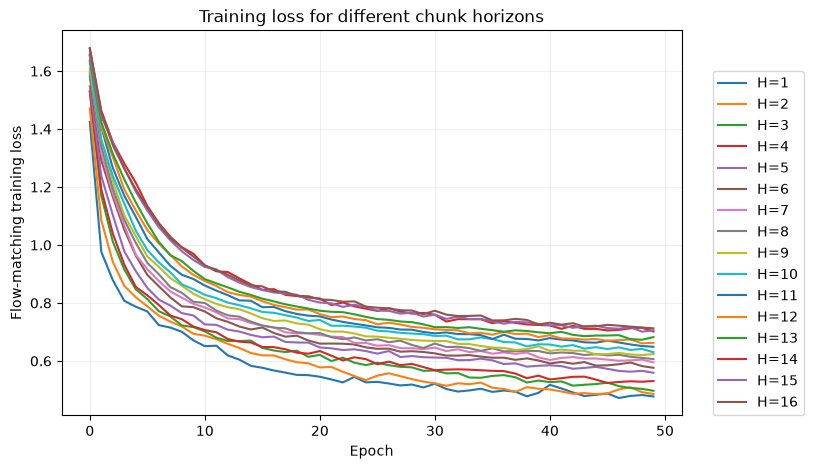

In [44]:
plt.figure(figsize=(8, 5))

for H in H_VALUES:
    plt.plot(
        models_h[H]["losses"],
        label=f"H={H}",
    )

plt.xlabel("Epoch")
plt.ylabel("Flow-matching training loss")
plt.title("Training loss for different chunk horizons")
plt.legend(loc = (1.05, 0.0), fontsize=10)
plt.grid(alpha=0.2)
plt.show()

## 33. Effect of $H$ when replanning every step

Setting $K=1$ means every model replans after every environment step.

Therefore this plot isolates the effect of training the policy to generate increasingly long action chunks.

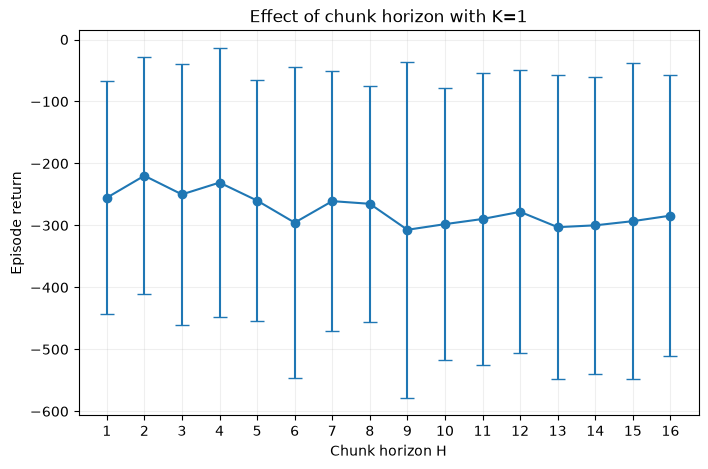

In [45]:
H_K1 = [H for H in H_VALUES if (H, 1) in hk_results]

means_k1 = [hk_results[(H, 1)]["mean"] for H in H_K1]
stds_k1 = [hk_results[(H, 1)]["std"] for H in H_K1]

plt.figure(figsize=(8, 5))

plt.errorbar(
    H_K1,
    means_k1,
    yerr=stds_k1,
    marker="o",
    capsize=5,
)

plt.xlabel("Chunk horizon H")
plt.ylabel("Episode return")
plt.title("Effect of chunk horizon with K=1")
plt.xticks(H_K1)
plt.grid(alpha=0.2)
plt.show()

## 34. Effect of replanning interval $K$ for each $H$

For a fixed $H$, increasing $K$ makes execution progressively more open-loop.

At $K=1$ we replan every step; at $K=H$ the complete generated chunk is executed before replanning.

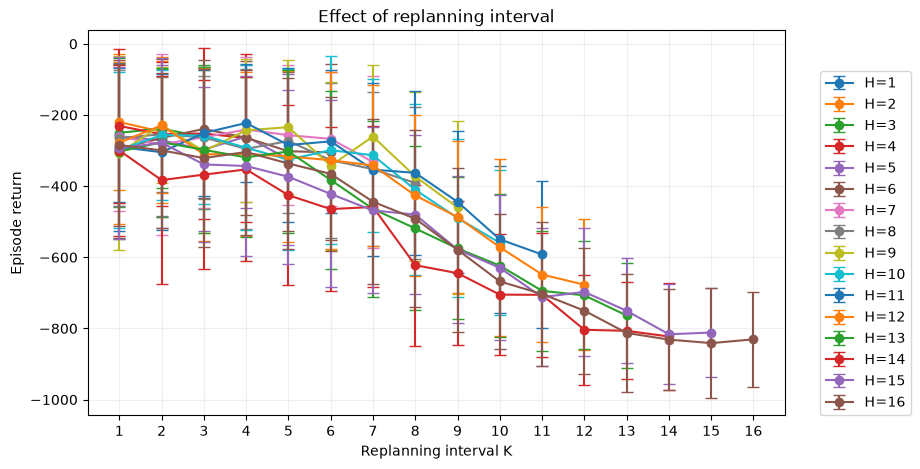

In [46]:
plt.figure(figsize=(9, 5))

for H in H_VALUES:
    valid_K = [K for K in K_CANDIDATES if (H, K) in hk_results]

    means = [hk_results[(H, K)]["mean"] for K in valid_K]
    stds = [hk_results[(H, K)]["std"] for K in valid_K]

    plt.errorbar(
        valid_K,
        means,
        yerr=stds,
        marker="o",
        capsize=4,
        label=f"H={H}",
    )

plt.xlabel("Replanning interval K")
plt.ylabel("Episode return")
plt.title("Effect of replanning interval")
plt.xticks(K_CANDIDATES)
plt.legend(loc = (1.05, 0.0), fontsize=10)
plt.grid(alpha=0.2)
plt.show()

## 35. Episode-return comparison for all $(H,K)$ settings

This reproduces the bar-chart style used earlier in the notebook, but now for the full grid of chunking settings.

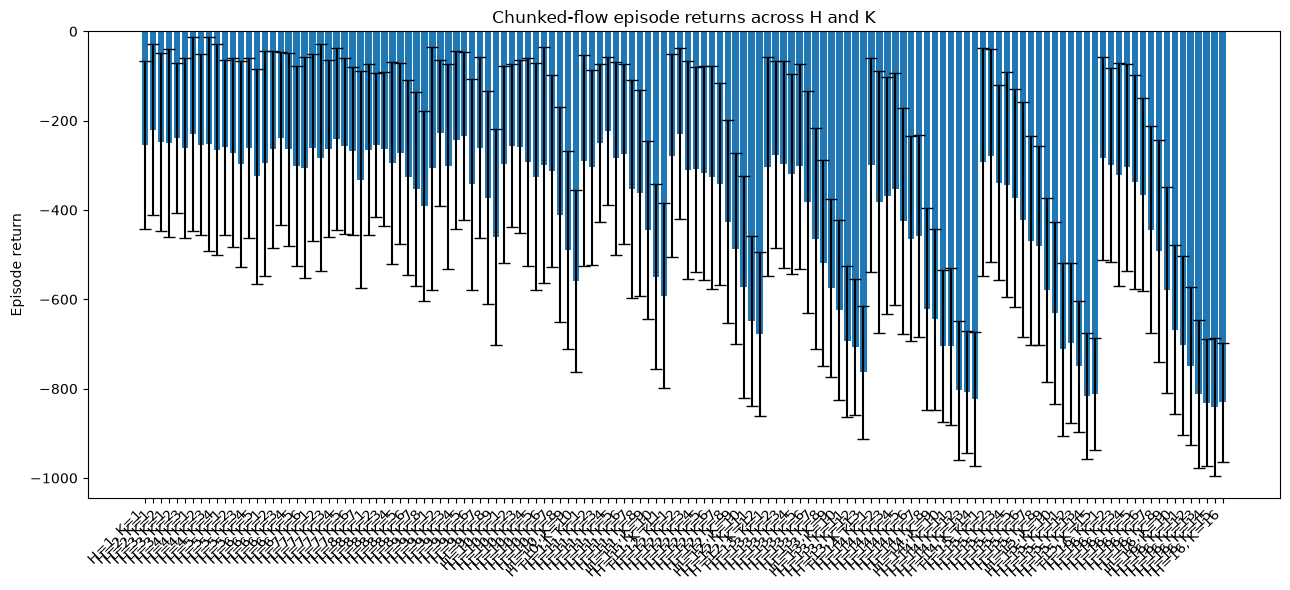

In [47]:
labels, means, stds = [], [], []

for H in H_VALUES:
    for K in K_CANDIDATES:
        if (H, K) not in hk_results:
            continue

        labels.append(f"H={H}, K={K}")
        means.append(hk_results[(H, K)]["mean"])
        stds.append(hk_results[(H, K)]["std"])

plt.figure(figsize=(13, 6))

plt.bar(
    np.arange(len(labels)),
    means,
    yerr=stds,
    capsize=4,
)

plt.xticks(
    np.arange(len(labels)),
    labels,
    rotation=45,
    ha="right",
)

plt.ylabel("Episode return")
plt.title("Chunked-flow episode returns across H and K")
plt.tight_layout()
plt.show()

## 36. Episode-return histograms for different $H$ at $K=1$

Unlike the previous bar plot, these are actual histograms of the return distributions.

Holding $K=1$ fixed isolates the effect of chunk horizon.

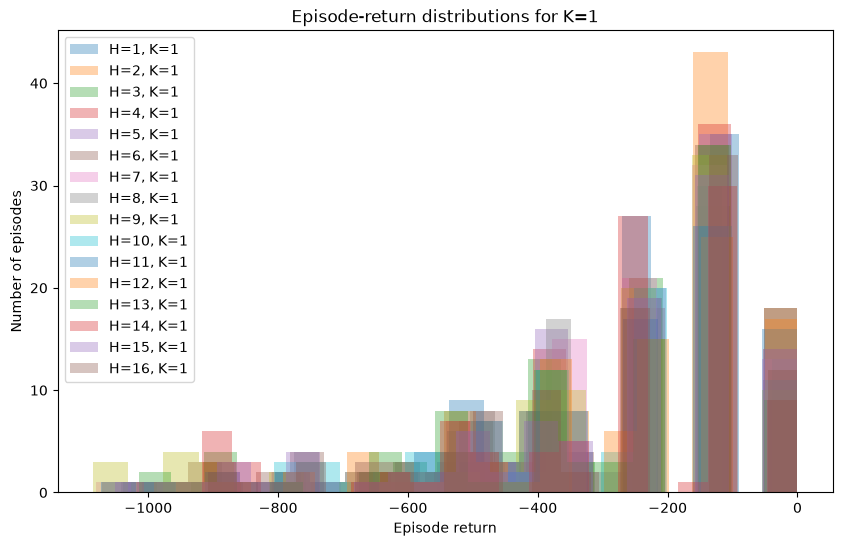

In [48]:
plt.figure(figsize=(10, 6))

for H in H_VALUES:
    returns = hk_results[(H, 1)]["returns"]

    plt.hist(
        returns,
        bins=20,
        alpha=0.35,
        label=f"H={H}, K=1",
    )

plt.xlabel("Episode return")
plt.ylabel("Number of episodes")
plt.title("Episode-return distributions for K=1")
plt.legend()
plt.show()

## 37. Episode-return histograms for different $K$ at the baseline $H=8$

This keeps the original baseline horizon fixed and shows how behavior changes as execution becomes more open-loop.

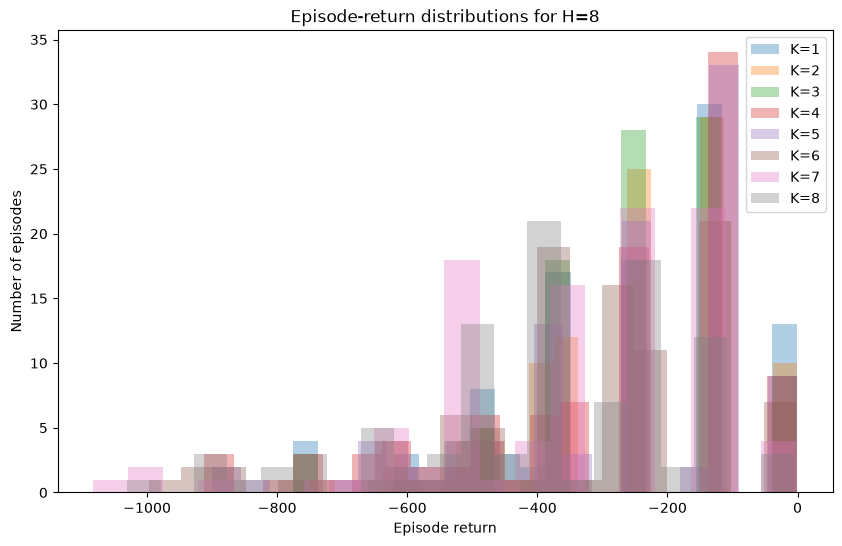

In [49]:
H_TO_PLOT = 8

plt.figure(figsize=(10, 6))

for K in K_CANDIDATES:
    if (H_TO_PLOT, K) not in hk_results:
        continue

    returns = hk_results[(H_TO_PLOT, K)]["returns"]

    plt.hist(
        returns,
        bins=20,
        alpha=0.35,
        label=f"K={K}",
    )

plt.xlabel("Episode return")
plt.ylabel("Number of episodes")
plt.title(f"Episode-return distributions for H={H_TO_PLOT}")
plt.legend()
plt.show()

## 38. Compact numerical summary

In [50]:
print(f"{'H':>4} {'K':>4} {'Mean return':>14} {'Std':>12}")
print("-" * 40)

for H in H_VALUES:
    for K in K_CANDIDATES:
        if (H, K) not in hk_results:
            continue

        result = hk_results[(H, K)]

        print(
            f"{H:4d} "
            f"{K:4d} "
            f"{result['mean']:14.1f} "
            f"{result['std']:12.1f}"
        )

   H    K    Mean return          Std
----------------------------------------
   1    1         -255.3        187.9
   2    1         -219.8        191.3
   2    2         -247.1        199.1
   3    1         -250.0        210.0
   3    2         -238.4        168.1
   3    3         -261.9        201.2
   4    1         -230.9        217.2
   4    2         -254.0        202.8
   4    3         -252.1        240.4
   4    4         -264.8        236.5
   5    1         -260.0        194.9
   5    2         -271.3        212.2
   5    3         -297.1        230.0
   5    4         -260.5        201.6
   5    5         -324.4        240.9
   6    1         -295.5        251.4
   6    2         -264.3        221.2
   6    3         -239.3        193.6
   6    4         -264.0        216.4
   6    5         -301.9        223.7
   6    6         -305.0        247.4
   7    1         -260.8        209.5
   7    2         -282.6        254.9
   7    3         -262.7        197.7
   7    4

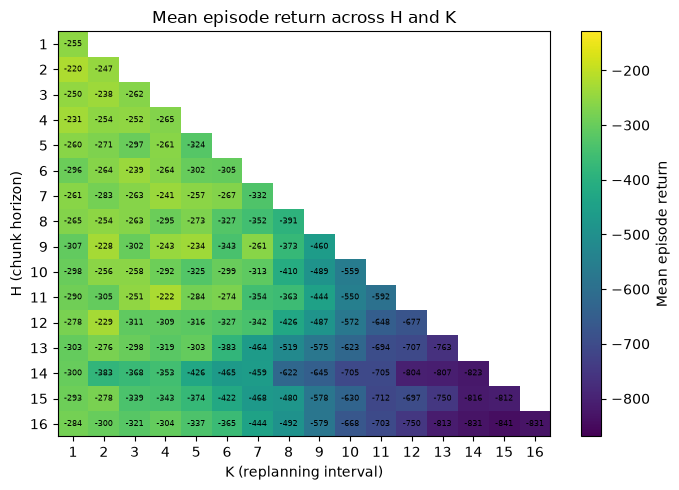

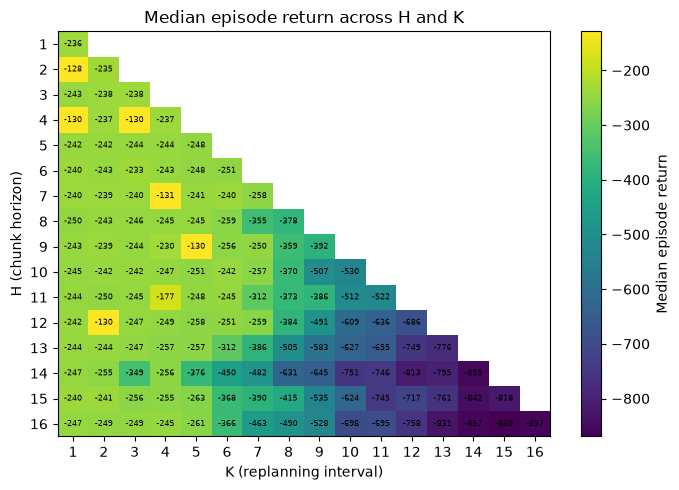

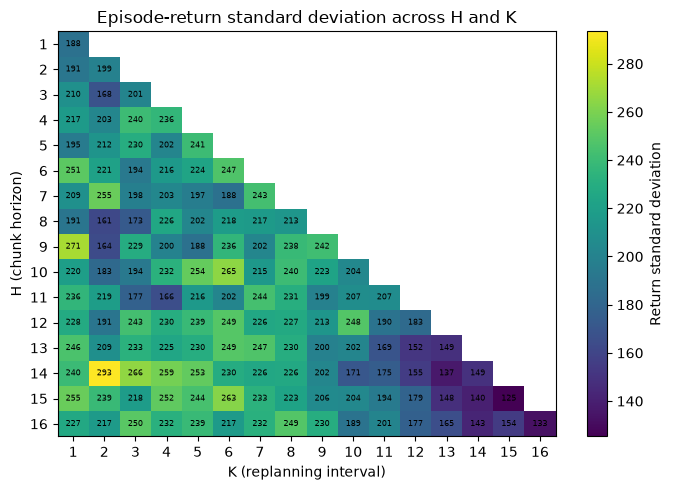

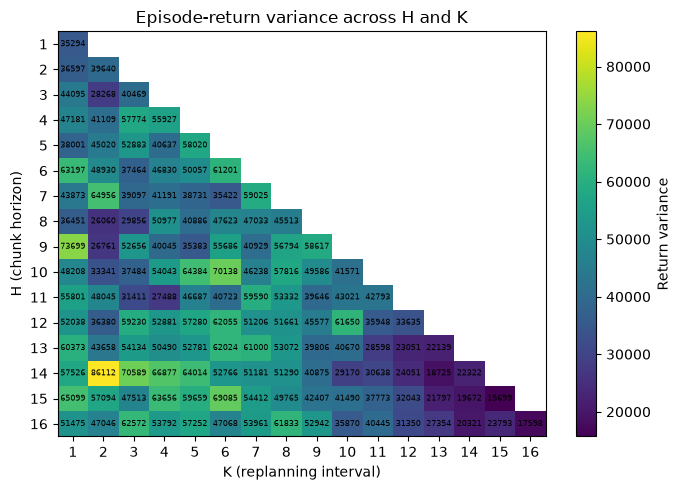

In [52]:
# ============================================================
# H-K matrices and heatmaps
# Mean and median share the SAME colorbar scale.
# Std and variance use their own scales.
# ============================================================

mean_matrix   = np.full((len(H_VALUES), len(K_CANDIDATES)), np.nan)
median_matrix = np.full((len(H_VALUES), len(K_CANDIDATES)), np.nan)
std_matrix    = np.full((len(H_VALUES), len(K_CANDIDATES)), np.nan)
var_matrix    = np.full((len(H_VALUES), len(K_CANDIDATES)), np.nan)

for i, H in enumerate(H_VALUES):
    for j, K in enumerate(K_CANDIDATES):
        if (H, K) in hk_results:
            returns = hk_results[(H, K)]["returns"]

            mean_matrix[i, j]   = np.mean(returns)
            median_matrix[i, j] = np.median(returns)
            std_matrix[i, j]    = np.std(returns)
            var_matrix[i, j]    = np.var(returns)


def plot_hk_matrix(
    matrix,
    title,
    colorbar_label,
    value_format=".0f",
    vmin=None,
    vmax=None,
):
    plt.figure(figsize=(7, 5))

    im = plt.imshow(
        matrix,
        aspect="auto",
        vmin=vmin,
        vmax=vmax,
    )

    plt.colorbar(im, label=colorbar_label)

    plt.xticks(range(len(K_CANDIDATES)), K_CANDIDATES)
    plt.yticks(range(len(H_VALUES)), H_VALUES)

    plt.xlabel("K (replanning interval)")
    plt.ylabel("H (chunk horizon)")
    plt.title(title)

    for i in range(len(H_VALUES)):
        for j in range(len(K_CANDIDATES)):
            if not np.isnan(matrix[i, j]):
                plt.text(
                    j,
                    i,
                    format(matrix[i, j], value_format),
                    ha="center",
                    va="center",
                    fontsize=6,
                )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Mean and median use one shared return scale.
# ------------------------------------------------------------
return_vmin = np.nanmin(
    np.concatenate([
        mean_matrix[np.isfinite(mean_matrix)],
        median_matrix[np.isfinite(median_matrix)],
    ])
)

return_vmax = np.nanmax(
    np.concatenate([
        mean_matrix[np.isfinite(mean_matrix)],
        median_matrix[np.isfinite(median_matrix)],
    ])
)


plot_hk_matrix(
    mean_matrix,
    "Mean episode return across H and K",
    "Mean episode return",
    vmin=return_vmin,
    vmax=return_vmax,
)

plot_hk_matrix(
    median_matrix,
    "Median episode return across H and K",
    "Median episode return",
    vmin=return_vmin,
    vmax=return_vmax,
)


# ------------------------------------------------------------
# Std and variance use their own natural color scales.
# ------------------------------------------------------------
plot_hk_matrix(
    std_matrix,
    "Episode-return standard deviation across H and K",
    "Return standard deviation",
)

plot_hk_matrix(
    var_matrix,
    "Episode-return variance across H and K",
    "Return variance",
)

# Suggested experiments after the baseline works

Once this notebook runs end-to-end, the natural next experiments are:

- chunk horizon $H\in\{1,4,8,16\}$,
- execute $K>1$ actions before replanning,
- compare Euler, Heun, and Tsit5,
- vary the number of expert demonstrations,
- compare deterministic expert actions with stochastic PPO samples,
- add Gaussian behavioral cloning,
- add DAgger,
- move the same code to a multidimensional continuous-control environment such as Reacher.

The important conceptual progression is

$$
\text{Expert}
\rightarrow
\text{BC}
\rightarrow
\text{Generative one-step policy}
\rightarrow
\text{Generative action trajectory}.
$$